Original Image Size: 4791720 bits
Compressed Size: 4578336 bits
Compression Ratio: 1.0466073263299156


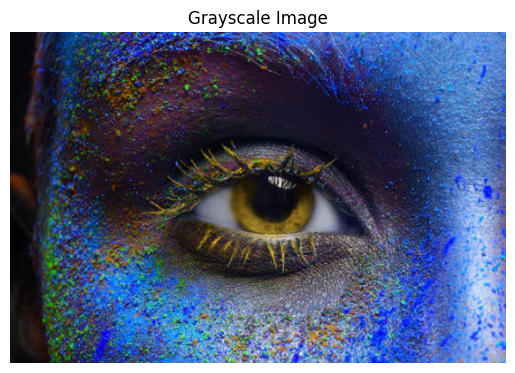

In [3]:
#Image Compression using hulffman Encoding
import cv2
import numpy as np
import heapq
from collections import Counter
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread('/content/eye.jpeg')

if img is None:
    print("Image not found!")
else:
    # Calculate pixel frequencies
    pixels = img.flatten()
    freq = Counter(pixels)

    # Build Huffman Tree
    heap = [[count, [pixel, ""]] for pixel, count in freq.items()]
    heapq.heapify(heap)

    while len(heap) > 1:
        low = heapq.heappop(heap)
        high = heapq.heappop(heap)

        for pair in low[1:]:
            pair[1] = '0' + pair[1]

        for pair in high[1:]:
            pair[1] = '1' + pair[1]

        heapq.heappush(heap, [low[0] + high[0]] + low[1:] + high[1:])

    # Generate Huffman codes
    huffman_codes = dict(heap[0][1:])

    # Encode image
    encoded_data = ''.join(huffman_codes[p] for p in pixels)

    # Display results
    print("Original Image Size:", img.size * 8, "bits")
    print("Compressed Size:", len(encoded_data), "bits")
    print("Compression Ratio:", (img.size * 8) / len(encoded_data))

    # Display original image using matplotlib instead of cv2.imshow
    plt.imshow(img, cmap='gray')
    plt.title("Grayscale Image")
    plt.axis('off')
    plt.show()